<a href="https://colab.research.google.com/github/speediedan/interpretune/blob/main/src/it_examples/notebooks/publish/sasa_blocks/sasa_blocks_frames_charts.ipynb">
  <img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab" />
</a>

# Block-Sparse Featurizers: SASA Blocks, Frames and Charts on Mistral-7B

Subspace-aware sparse autoencoders <a id="cite-1"></a>[[1]](#ref-1) (SASA) replace each SAE feature's single decoder
direction with a small block of directions that activate together. In the released Mistral-7B model, one block of
eight directions at layer 8 responds to month names and another to weekdays. The paper tests both causally: removing
a block's span at a name halves the probability that the model names a month (or weekday) when it repeats the
sentence, and adding the block's mean contribution writes the concept in.

Interpretune addresses a block exactly as it addresses an SAE feature: block $g$ of a model with block size $b$ is the
decoder range $[g b, (g + 1) b)$, and $b = 1$ is an ordinary SAE. Coordinates inside a block are never addressed
directly, because any rotation of them spans the same subspace. Instead a named, versioned **frame** reads them, and a
**chart** on the frame edits them in its own coordinates, here a plane read as a radius and an angle.

This notebook:

- **Replicates the paper's causal tables** (its Tables 13 and 14) through the model backend's native `reject` and
  `add` at the name's position, with the paper's controls.
- **Asks what the paper leaves open:** whether the coordinates inside a block carry *which* month it is. It fits a
  frame and a chart to the month block, checks that the months form a ring, and moves a month around the ring.
- **Contrasts a block with a named subspace** fitted the way Engels et al. <a id="cite-2"></a>[[2]](#ref-2) find
  circular features, on the same prompts.

Each section states the paper's claim (where it makes one), our measurement and a control. A closing section says
what transferred. The notebook needs a GPU with 24 GB; the model and the release are public on the Hugging Face Hub.

In [2]:
# @title Imports { display-mode: "form" }
import math

import matplotlib.pyplot as plt
import torch

from it_examples.utils.example_helpers import required_os_env
from it_examples.utils.nb_ui_utils import display_notebook_table
from it_examples.utils.sasa_blocks_helpers import (
    CARRIERS,
    CONCEPTS,
    PAPER_ADDITION,
    PAPER_REMOVAL,
    addition,
    calibrate_threshold,
    capture,
    carrier_states,
    chart_edits,
    edit_prompts,
    fit_ring,
    hand_written_removal,
    load_sasa,
    named_subspace,
    principal_cosines,
    removal,
    ring_order,
    screen_groups,
    single_token_id,
    steering_vectors,
)

src/interpretune/analysis/ops/dispatcher.py:1110: Alias 'ct_feature_intervention' already has an assigned op or alias so the alias specified by 'feature_intervention_forward' cannot be mapped to it
src/interpretune/analysis/ops/dispatcher.py:1110: Alias 'semantic_direction' already has an assigned op or alias so the alias specified by 'concept_direction' cannot be mapped to it
src/interpretune/analysis/ops/dispatcher.py:1110: Alias 'model_forward' already has an assigned op or alias so the alias specified by 'model_fwd' cannot be mapped to it
src/interpretune/analysis/ops/dispatcher.py:1110: Alias 'jacobian_lens_read' already has an assigned op or alias so the alias specified by 'jlens_read' cannot be mapped to it
src/interpretune/analysis/ops/dispatcher.py:1110: Alias 'jacobian_lens_concept_probe' already has an assigned op or alias so the alias specified by 'jlens_concept_probe' cannot be mapped to it
src/interpretune/analysis/ops/dispatcher.py:1110: Alias 'jacobian_lens_sparse_inven

## Notebook Parameters

This cell contains parameters that can be injected by papermill during parameterized test runs. `n_background_docs`
Pile-10k documents calibrate the release's per-token group gate and serve as background for the group screen.
`max_edit_prompts` caps the prompts per concept and task in the chart-edit section (`None` runs all of them).

In [3]:
# Parameters - These will be injected by papermill during parameterized test runs
model_name = "mistralai/Mistral-7B-v0.1"
sasa_repo = "arshandalili/sasa-mistral-7b-layer8"
sasa_checkpoint = "sasa_r8_k10"
sasa_revision = "a16c662f81cbabd8949726fa299717bb7776a9c3"  # the release commit this notebook was rendered at
device = "cuda:0"
n_background_docs = 40
max_edit_prompts = None
seed = 0

In [4]:
# @title Environment Setup { display-mode: "form" }
env_path: str | None = None  # set to '/full/path/to/.env' to override
os_env_reqs = None
assert required_os_env(env_path=env_path, env_reqs=os_env_reqs)
torch.manual_seed(seed)

## The Model, Its Backend and the Release

The model is loaded through nnsight and driven through `NNsightModelBackend`, the model-level surface the analysis ops
use. Nothing trains, so gradients stay off.

The SASA release is an SAELens-format checkpoint at `blocks.8.hook_resid_pre` (the residual stream entering block 8,
which interpretune also spells `blocks.8.hook_in`): 4,096 groups of rank 8. It is read directly from its safetensors,
so the `sasa` package is not needed. SASA layer-normalizes each token before encoding, which the helpers do the same
way.

In [5]:
from nnsight import TransformersModel

from interpretune.adapters.nnsight.backends import NNsightModelBackend
from interpretune.analysis.backends.hook_mapping import HookNameResolver

lm = TransformersModel(model_name, task="text-generation", device_map=device, dispatch=True, dtype=torch.bfloat16)
hf_model = lm._module
hf_model.requires_grad_(False)
torch.set_grad_enabled(False)
model, backend = lm, NNsightModelBackend(HookNameResolver(type(hf_model).__name__))
tokenizer = lm.tokenizer

release = load_sasa(sasa_repo, sasa_checkpoint, device=device, revision=sasa_revision)
site = f"blocks.{release.layer}.hook_in"
d_model = release.w_dec.shape[1]
print(f"{model_name}: {hf_model.config.num_hidden_layers} layers; {sasa_checkpoint}: {release.n_groups} groups of rank")
print(f"{release.rank} at {site} ({release.w_dec.shape[0]} decoder rows of width {d_model})")

Loading weights:   0%|          | 0/291 [00:00<?, ?it/s]

mistralai/Mistral-7B-v0.1: 32 layers; sasa_r8_k10: 4096 groups of rank
8 at blocks.8.hook_in (32768 decoder rows of width 4096)


## Addressing a Block, and Finding the Month and Weekday Blocks

The release enters a `LatentCatalog` as one `LatentBinding` with block size 8, so `features:sasa & units:[g]` selects
group $g$ as one block, the same form that selects one feature of an SAE.

**The paper's selection:** for each concept, the group whose pre-activation norm best separates the concept's names
from background tokens (AUROC); the runner-up group is a same-concept control. The paper's Figure 1 names group 3810
as the month group.

**Our measurement:** the same AUROC with the names in the paper's templates as positives and `n_background_docs`
Pile-10k documents as background (the paper uses natural Pile occurrences of the names). The same documents calibrate
the per-token gate, as the authors do for this checkpoint.

In [6]:
from datasets import load_dataset

from interpretune.analysis.venngram import LatentCatalog

texts = load_dataset("NeelNanda/pile-10k", split="train")["text"][:n_background_docs]
threshold = calibrate_threshold(model, backend, tokenizer, release, texts, site, device)
background = torch.cat(
    [
        capture(model, backend, {"input_ids": torch.tensor([tokenizer(t)["input_ids"][:512]], device=device)}, site)[
            0, 1:
        ]
        for t in texts[: max(1, n_background_docs // 4)]
    ]
)
screen = screen_groups(model, backend, tokenizer, release, background, site, device)

catalog = LatentCatalog([release.binding()])
display_notebook_table(
    [
        [
            concept,
            f"`features:sasa & units:[{s['group']}]`",
            f"{s['auroc'][0]:.4f}",
            s["runner_up"],
            f"{s['auroc'][1]:.4f}",
            str(catalog.resolve(f"features:sasa & units:[{s['group']}]", n_layers=32).targets[0]),
        ]
        for concept, s in screen.items()
    ],
    ["concept", "address", "AUROC", "runner-up group", "AUROC", "resolved target"],
    title="The selected groups",
    caption=f"Per-token gate calibrated on {len(texts)} Pile-10k documents: {threshold:.4f} (the release's: 6.2473).",
)

concept,address,AUROC,runner-up group,AUROC,resolved target
month,`features:sasa & units:[3810]`,0.9992,830,0.9975,"LatentTarget(kind='feature', name='sasa', layer=8, point='hook_in', unit=3810)"
day,`features:sasa & units:[2949]`,1.0000,2045,0.9754,"LatentTarget(kind='feature', name='sasa', layer=8, point='hook_in', unit=2949)"


### Control: the payload is the edit it claims to be

Before measuring, the removal payload (`reject` with the month group's eight decoder rows, at the name's position
only) is checked against the same edit written by hand as a forward pre-hook on the decoder layer. The two must agree to
bf16 rounding (the payload edits the bf16 activation; the hand-written edit computes in double precision), and the
edit must move the logits by much more than that.

The paper removes the span from the *layer-normalized* state and then undoes the normalization, while `reject` acts
on the raw state. The two differ by the projection of the token's mean onto the span, so the paper's form is
measured beside it.

In [7]:
from interpretune.analysis.backends.interventions import InterventionSpec

template = "The event happened in {t}. The event happened in"
probe = {
    "input_ids": torch.tensor([tokenizer(template.format(t=m))["input_ids"] for m in CONCEPTS["month"]], device=device)
}
column = len(tokenizer(template.split("{t}")[0] + "January")["input_ids"]) - 1
rows = release.block(screen["month"]["group"])
payload = {site: InterventionSpec(rows[None], op="reject", position_scope="positions", positions=(column,))}
clean, edited = backend.fwd_w_intervention(model, probe, payload)
manual = hand_written_removal(hf_model, probe["input_ids"], column, rows, release.layer, normalized=False)
paper = hand_written_removal(hf_model, probe["input_ids"], column, rows, release.layer, normalized=True)
err = (manual[:, -1].float() - edited[:, -1].float()).abs().max().item()
moved = (clean[:, -1].float() - edited[:, -1].float()).abs().max().item()
gap = (paper[:, -1].float() - edited[:, -1].float()).abs().max().item()
ids = [single_token_id(tokenizer, m) for m in CONCEPTS["month"]]
mass = {
    k: float(v[:, -1].float().softmax(-1)[:, ids].sum(-1).mean())
    for k, v in (("clean", clean), ("payload", edited), ("by hand", manual), ("paper's form", paper))
}
print(f"payload vs hand-written edit: max |logit difference| {err:.3f}; the edit moved the logits by up to {moved:.2f}")
print(f"raw-state reject vs the paper's normalized removal: max |logit difference| {gap:.3f}")
print("P(months): " + ", ".join(f"{k} {v:.1%}" for k, v in mass.items()))
# the payload edits the bf16 activation and the hand-written edit computes in double precision, so they agree to
# bf16 rounding, small against what the edit moves
assert moved > 1.0 and err < 0.1 * moved and abs(mass["payload"] - mass["by hand"]) < 0.01

payload vs hand-written edit: max |logit difference| 0.225; the edit moved the logits by up to 6.10
raw-state reject vs the paper's normalized removal: max |logit difference| 0.188
P(months): clean 63.9%, payload 28.2%, by hand 28.1%, paper's form 28.1%


## The Paper's Table 14: Removing a Block

**The paper's claim:** removing the month group's decoder span at the earlier name lowers P(C), the total probability
of the twelve month names at the completion, from 86.1% to 40.9% (weekdays: 90.0% to 45.2%). The runner-up group, the
other concept's group and a random 8-dimensional subspace leave it nearly unchanged.

**Our measurement:** the paper's 16 templates per concept with every member, `reject` at the name's position through
the model backend.

In [8]:
removal_rows = []
for concept in CONCEPTS:
    ours = removal(model, backend, tokenizer, release, concept, screen, site, device, seed=seed)
    for edit, paper_value in PAPER_REMOVAL[concept].items():
        removal_rows.append([concept, edit, f"{ours[edit]:.1f}%", f"{paper_value:.1f}%"])
display_notebook_table(
    removal_rows,
    ["concept", "removed at the name", "P(C), ours", "P(C), paper"],
    title="Table 14: removal",
    caption="P(C) averaged over templates; each template is averaged over its members first.",
)

concept,removed at the name,"P(C), ours","P(C), paper"
month,unsteered,86.1%,86.1%
month,selected group,40.9%,40.9%
month,runner-up group,85.4%,85.9%
month,other concept's group,84.8%,84.7%
month,random 8-d subspace,86.1%,86.1%
day,unsteered,89.9%,90.0%
day,selected group,45.2%,45.2%
day,runner-up group,89.6%,88.1%
day,other concept's group,88.9%,88.9%
day,random 8-d subspace,90.0%,90.0%


## The Paper's Table 13: Adding a Block

**The paper's claim:** replacing the name with an unrelated noun drops P(C) to about 5%. Adding the group's mean
contribution $v_k$ (estimated on four templates) at the noun, scaled by $\alpha$, raises it to 34.6% at $\alpha = 1$
and 78.7% at $\alpha = 2$ for months (weekdays: 52.0% and 80.1%). Control vectors of the same norm barely move it.

**Our measurement:** the twelve held-out templates with eight nouns each, `add` at the noun's position.

In [9]:
vectors = steering_vectors(model, backend, tokenizer, release, screen, site, device)
addition_rows = []
for concept in CONCEPTS:
    ours = addition(model, backend, tokenizer, release, concept, vectors, site, device)
    paper = PAPER_ADDITION[concept]
    addition_rows.append([concept, "unsteered", f"{ours['unsteered']:.1f}%", "", f"{paper['unsteered']:.1f}%", ""])
    for edit in ("selected group", "runner-up group", "other concept's group", "random vector"):
        addition_rows.append(
            [
                concept,
                edit,
                f"{ours[edit][1.0]:.1f}%",
                f"{ours[edit][2.0]:.1f}%",
                f"{paper[edit][1.0]:.1f}%",
                f"{paper[edit][2.0]:.1f}%",
            ]
        )
display_notebook_table(
    addition_rows,
    ["concept", "vector added at the noun", "ours, α = 1", "ours, α = 2", "paper, α = 1", "paper, α = 2"],
    title="Table 13: addition",
    caption="Every vector is scaled to the selected group's norm before α.",
)

concept,vector added at the noun,"ours, α = 1","ours, α = 2","paper, α = 1","paper, α = 2"
month,unsteered,5.6%,,5.6%,
month,selected group,34.6%,78.7%,34.6%,78.7%
month,runner-up group,7.0%,13.5%,6.1%,7.2%
month,other concept's group,8.3%,7.2%,8.3%,7.2%
month,random vector,5.5%,5.8%,5.6%,5.9%
day,unsteered,5.0%,,5.0%,
day,selected group,52.1%,80.2%,52.0%,80.1%
day,runner-up group,4.2%,4.0%,5.8%,11.3%
day,other concept's group,12.0%,8.7%,12.0%,8.7%
day,random vector,5.2%,5.8%,5.4%,5.9%


## Frames and Charts: Is There a Ring Inside the Block?

The paper shows (its Figure 1) that the per-month centroids of the month group's codes form a ring in calendar order,
and it names finding meaningful coordinates inside a group as open work. A frame and a chart make that question
concrete:

- **A frame** for the month block: an orthonormal basis of its eight decoder rows' span, named and versioned, and
  checked against the block's current decoder rows every time it is used.
- **A chart** on that frame: a `pca_plane` fitted to the members' centroids (the name's state in frame coordinates,
  averaged per member over six carrier sentences kept apart from every test prompt), read as a radius and an angle.
- **A named subspace** for contrast, fitted the way Engels et al. find circular features: the top eight principal
  directions of the same name states after removing each sentence's mean, registered as `subspace:months_pca` with its
  own frame and chart.

The measurement: do the members' angles run in calendar order, and how much of the block does the named subspace
share (cosines of the principal angles between the two spans)?

In [10]:
from interpretune.analysis.venngram import LatentChart, LatentFrame, SubspaceBinding

rings, frames, charts, subspaces = {}, [], [], []
for concept in CONCEPTS:
    states, labels = carrier_states(model, backend, tokenizer, concept, site, device)
    basis = named_subspace(states, labels, len(CARRIERS[concept]), release.rank)
    subspaces.append(SubspaceBinding(f"{concept}s_pca", release.layer, "hook_resid_pre", basis))
    rings[concept] = {"states": states, "labels": labels, "basis": basis}

catalog = LatentCatalog([release.binding()], subspaces)
for concept in CONCEPTS:
    block = catalog.resolve(f"features:sasa & units:[{screen[concept]['group']}]", n_layers=32).targets[0]
    named = catalog.resolve(f"subspace:{concept}s_pca", n_layers=32).targets[0]
    for kind, target in (("block", block), ("subspace", named)):
        rows = torch.linalg.qr(catalog.basis(target).double().T)[0].T.float()
        frame = LatentFrame(f"{concept}_{kind}", "v1", target, rows)
        frames.append(frame)
        fit = fit_ring(rings[concept]["states"] @ rows.T, rings[concept]["labels"])
        params = {"origin": fit["origin"], "axes": fit["axes"]}
        charts.append(
            LatentChart(
                f"{concept}_{kind}_ring", "v1", "pca_plane", target, frame.name, "v1", 2, {1: 2 * math.pi}, params
            )
        )
        # the control chart: the same origin and a plane inside the frame orthogonal to the fitted one
        gen = torch.Generator().manual_seed(seed)
        noise = torch.randn(len(rows), 2, generator=gen, dtype=torch.float64).to(fit["axes"].device)
        q = torch.linalg.qr(torch.cat([fit["axes"].T.double(), noise], 1))[0]
        off = {"origin": fit["origin"], "axes": q[:, 2:4].T.float()}
        charts.append(
            LatentChart(f"{concept}_{kind}_off", "v1", "pca_plane", target, frame.name, "v1", 2, {1: 2 * math.pi}, off)
        )
        rings[concept][kind] = {"target": target, "fit": fit}

catalog = LatentCatalog([release.binding()], subspaces, frames=frames, charts=charts)
ring_rows = []
for concept in CONCEPTS:
    for kind in ("block", "subspace"):
        entry = rings[concept][kind]
        centroids = entry["fit"]["centroids"]
        # the centroids back in site space, read through the chart: radius and angle per member
        rows = catalog.frame(entry["target"], name=f"{concept}_{kind}", version="v1").rows.to(centroids)
        point = catalog.chart_coordinates(
            entry["target"], centroids @ rows, chart=f"{concept}_{kind}_ring", version="v1"
        )
        entry["radius"], entry["angles"] = point[:, 0], point[:, 1]
        order = ring_order(entry["angles"].tolist())
        ring_rows.append(
            [
                concept,
                kind,
                order["in order"],
                order["winding"],
                order["largest gap (deg)"],
                f"{entry['fit']['explained']:.0%}",
            ]
        )
display_notebook_table(
    ring_rows,
    ["concept", "target", "steps in calendar order", "winding", "largest gap (deg)", "centroid variance in the plane"],
    title="Do the members form a ring?",
)
for concept in CONCEPTS:
    cos = principal_cosines(release.block(screen[concept]["group"]), rings[concept]["basis"])
    print(f"{concept}: principal cosines, block vs named subspace: {cos}")

concept,target,steps in calendar order,winding,largest gap (deg),centroid variance in the plane
month,block,11 of 12,1.0,57.4,97%
month,subspace,12 of 12,1.0,55.3,58%
day,block,7 of 7,1.0,152.5,100%
day,subspace,7 of 7,1.0,86.1,75%


month: principal cosines, block vs named subspace: [0.902, 0.822, 0.243, 0.128, 0.077, 0.056, 0.03, 0.0]
day: principal cosines, block vs named subspace: [0.888, 0.198, 0.113, 0.081, 0.065, 0.06, 0.021, 0.015]


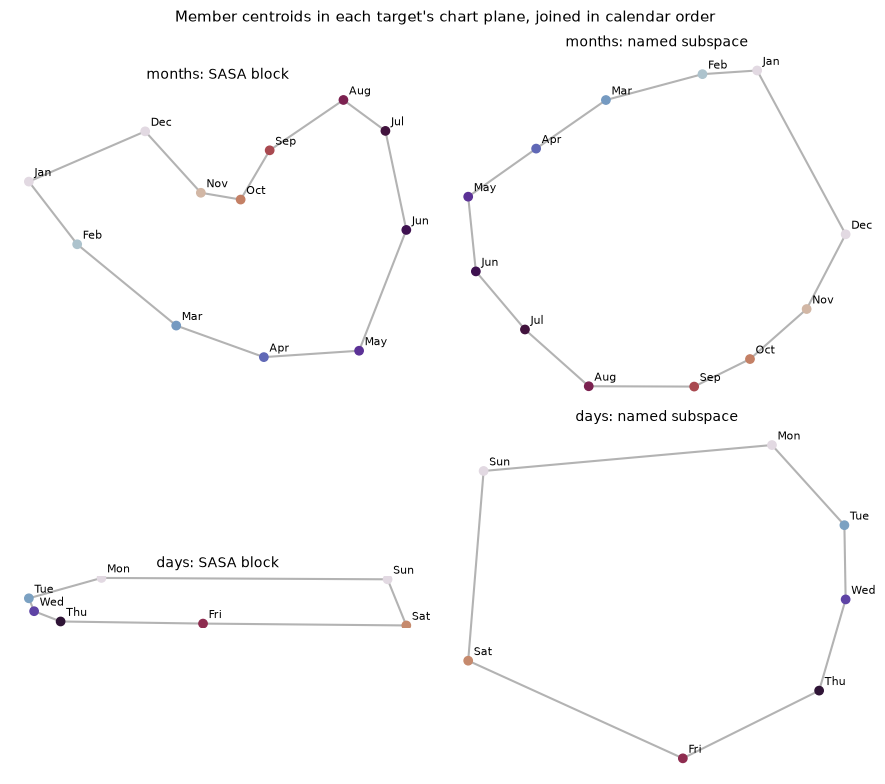

In [11]:
fig, axes = plt.subplots(2, 2, figsize=(9, 8))
for row, concept in enumerate(CONCEPTS):
    for col, kind in enumerate(("block", "subspace")):
        entry, ax = rings[concept][kind], axes[row][col]
        angles, radius = entry["angles"].cpu(), entry["radius"].cpu()
        x, y = radius * torch.cos(angles), radius * torch.sin(angles)
        ax.plot(torch.cat([x, x[:1]]), torch.cat([y, y[:1]]), color="0.7", zorder=1)
        ax.scatter(x, y, c=range(len(x)), cmap="twilight", zorder=2)
        for name, xi, yi in zip(CONCEPTS[concept], x, y):
            ax.annotate(name[:3], (float(xi), float(yi)), textcoords="offset points", xytext=(4, 4), fontsize=8)
        ax.set_title(f"{concept}s: {'SASA block' if kind == 'block' else 'named subspace'}", fontsize=10)
        ax.set_aspect("equal")
        ax.axis("off")
fig.suptitle("Member centroids in each target's chart plane, joined in calendar order", fontsize=11)
fig.tight_layout()
plt.show()

## Moving a Member Around the Ring

**The question the paper leaves open:** do coordinates inside the block carry which member it is, so that moving a
point around the ring moves the model's answer?

**Our measurement:** at the earlier name's position, four edits move member $i$ toward member $i + 1$, and the
answer the model should then give shifts by one:

- **`set` the angle** on the target's chart to member $i + 1$'s angle, keeping the radius and every frame coordinate
  off the chart (`apply_site_chart(op="set")`);
- **patch the whole target** to member $i + 1$'s centroid, keeping everything off the target
  (`replace_site_coordinates`);
- **control: rotate an orthogonal plane** of the same frame by the same angle (a second chart, `op="rotate"`);
- **control: a random direction** of the same size as the `set` edit.

Each edit is written back with `replace` at that position, once per target (the SASA block, then the named subspace),
on two tasks: copying the name ("The event happened in March. The event happened in"), and calendar arithmetic
("Two months from March is"), where the answer depends on where the name sits on the cycle.

In [12]:
def edits_for(concept: str, kind: str) -> dict:
    entry = rings[concept][kind]
    target, n = entry["target"], len(CONCEPTS[concept])
    ring, off, frame = f"{concept}_{kind}_ring", f"{concept}_{kind}_off", f"{concept}_{kind}"
    gen = torch.Generator().manual_seed(seed)

    def set_angle(h, i):
        point = catalog.chart_coordinates(target, h[None], chart=ring, version="v1")[0]
        value = torch.stack([point[0], entry["angles"][(i + 1) % n].to(point)])
        return catalog.apply_site_chart(target, h[None], chart=ring, version="v1", op="set", value=value)[0]

    def patch(h, i):
        centroid = entry["fit"]["centroids"][(i + 1) % n].to(h)
        return catalog.replace_site_coordinates(target, h[None], centroid[None], frame=frame, version="v1")[0]

    def rotate_off(h, i):
        turn = float(entry["angles"][(i + 1) % n] - entry["angles"][i])
        return catalog.apply_site_chart(target, h[None], chart=off, version="v1", op="rotate", by={1: turn})[0]

    def random_direction(h, i):
        step = set_angle(h, i) - h
        direction = torch.randn(h.shape[-1], generator=gen).to(h)
        return h + direction / direction.norm() * step.norm()

    return {
        f"{kind}: set angle": set_angle,
        f"{kind}: patch target": patch,
        f"{kind}: rotate orthogonal plane": rotate_off,
        f"{kind}: random direction": random_direction,
    }


edit_rows = []
for task in ("copy", "arithmetic"):
    for concept in CONCEPTS:
        prompts = edit_prompts(tokenizer, concept, task)
        if max_edit_prompts is not None:
            prompts = prompts[:: max(1, len(prompts) // max_edit_prompts)][:max_edit_prompts]
        ids = [single_token_id(tokenizer, name) for name in CONCEPTS[concept]]
        edits = {**edits_for(concept, "block"), **edits_for(concept, "subspace")}
        table = chart_edits(model, backend, tokenizer, prompts, edits, ids, site, device)
        for edit, row in table.items():
            edit_rows.append(
                [
                    task,
                    concept,
                    edit,
                    f"{row['P(answer)']:.1f}%",
                    f"{row['P(shifted answer)']:.1f}%",
                    f"{row['shifted is top']:.1f}%",
                ]
            )
display_notebook_table(
    edit_rows,
    ["task", "concept", "edit at the name", "P(answer)", "P(shifted answer)", "shifted answer is the top member"],
    title="Moving a member one step around its ring",
    caption="The answer is the member the unedited model should name; the shifted answer is the next one on the cycle.",
)

task,concept,edit at the name,P(answer),P(shifted answer),shifted answer is the top member
copy,month,none,67.8%,5.3%,0.0%
copy,month,block: set angle,66.7%,5.8%,0.0%
copy,month,block: patch target,66.9%,5.8%,0.0%
copy,month,block: rotate orthogonal plane,67.7%,5.4%,0.0%
copy,month,block: random direction,67.7%,5.3%,0.0%
copy,month,subspace: set angle,66.4%,5.8%,0.0%
copy,month,subspace: patch target,16.1%,50.8%,72.9%
copy,month,subspace: rotate orthogonal plane,67.7%,5.2%,0.0%
copy,month,subspace: random direction,67.7%,5.3%,0.0%
copy,day,none,62.6%,12.7%,12.5%


## What Transferred

- **The paper's causal tables replicate.** Removing the selected group's span at the name takes P(C) from 86.1% to
  40.9% for months and from 89.9% to 45.2% for weekdays, and adding its mean contribution at the noun writes the concept
  in (34.6% and 78.7% at $\alpha = 1$ and 2 for months, 52.1% and 80.2% for weekdays). Every selected-group value
  matches the paper's Tables 13 and 14 to within 0.1 points, here through native `reject` and `add` at one position
  rather than hand-written hooks. Removing the span from the raw state rather than the layer-normalized one changes
  the logits by at most 0.19 (P(months) 28.2% against 28.1%).
- **The runner-up controls are not the paper's groups.** The template screen ranks groups 830 (months) and 2045
  (weekdays) second, where the paper's runner-ups are groups 3752 and 1433, so those rows differ from the paper's
  (months at $\alpha = 2$: 13.5% against 7.2%; weekdays: 4.0% against 11.3%). They stay far below the selected group either way.
- **The block holds a ring, but not a handle on the member.** The months run around the block's chart plane in
  calendar order (11 of 12 steps, 97% of the centroids' variance in the plane); the weekdays keep their order but bunch,
  with one gap of 152 degrees between a workweek and a weekend. Yet neither a `set` of the angle nor a patch of the
  whole block to the next member's centroid moves the answer: the shifted answer becomes the top member in 0% of month
  prompts on the copy task (0% unedited) and at most 14% of weekday prompts (12.5% unedited). The block carries *that*
  a month is present, which the removal shows, not *which* month the model goes on to use.
- **The named subspace carries the member.** Patching the whole `subspace:months_pca` target to the next member's
  centroid makes the shifted answer the top member in 72.9% of month and 66.1% of weekday copy prompts, and in 52.8%
  and 39.7% of arithmetic prompts (2.8% and 1.6% unedited), where the same patch on the block does nothing measurable.
  The two targets share about two directions for months (principal cosines 0.90 and 0.82, then 0.24 or less) and one
  for weekdays.
- **The chart is a readout, not yet a lever.** Setting the angle in either target's plane moves the shifted answer by
  at most 8 points: the ring is visible in two coordinates, but the model's use of the member needs more of the
  subspace than the plane that shows it. A chart of higher intrinsic dimension is the natural next measurement.
- **Not replicated here:** the paper's absorption and member-prediction benchmarks, its GPT-2 comparisons, and the
  group screen on natural Pile occurrences (this notebook screens on the templates' names, and selects the same month
  group the paper's Figure 1 names).

### API gaps this example found

- Editing the earlier name's position needs an explicit position set, which the model backends gained for this work
  ([#987](https://github.com/speediedan/interpretune/issues/987)).
- A Mistral checkpoint resolved no activation point until its component map was added
  ([#1093](https://github.com/speediedan/interpretune/issues/1093)).
- A chart fitted on a GPU was refused by its own validation ([#1096](https://github.com/speediedan/interpretune/issues/1096)).
- A positions-scoped `replace` takes one operand for the whole batch, so a per-prompt chart edit runs one prompt at a
  time ([#1100](https://github.com/speediedan/interpretune/issues/1100)), and a chart edit runs as capture, edit, then
  `replace` rather than as one op in the forward pass.

## References

1. <a id="ref-1"></a>Seyed Arshan Dalili and Mehrdad Mahdavi. "Subspace-Aware Sparse Autoencoders for Effective
   Mechanistic Interpretability." NeurIPS 2026. arXiv:2606.06333.
   [arxiv.org/abs/2606.06333](https://arxiv.org/abs/2606.06333); code and the templates used here:
   [github.com/arshandalili/sasa](https://github.com/arshandalili/sasa) (MIT). [↩](#cite-1)
2. <a id="ref-2"></a>Joshua Engels, Eric J. Michaud, Isaac Liao, Wes Gurnee and Max Tegmark. "Not All Language Model
   Features Are One-Dimensionally Linear." arXiv:2405.14860, 2024.
   [arxiv.org/abs/2405.14860](https://arxiv.org/abs/2405.14860) [↩](#cite-2)